# Boosting GLM: complete Python example

This notebook demonstrates the full method on a reproducible synthetic motor-insurance portfolio. The workflow mirrors the original R project:

1. fit a conventional exposure-adjusted Poisson GLM;
2. fit a shallow Poisson gradient-boosting reference model;
3. extract marginal feature effects from the GBM;
4. auto-calibrate each effect with a small regression tree;
5. add selected interactions and combine the calibrated effects in a final regularized Poisson GLM;
6. evaluate predictive performance and fidelity to the GBM.

No external data or credentials are required.

In [1]:
import contextlib
import io
import os
import warnings
from pathlib import Path

os.environ.setdefault('LOKY_MAX_CPU_COUNT', '8')
warnings.filterwarnings('ignore', message='Could not find the number of physical cores.*')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from boosting_glm.data import split_dataset, synthetic_portfolio
from boosting_glm.metrics import model_metrics
from boosting_glm.model import BoostedGLM

pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
RANDOM_STATE = 42

## 1. Create an insurance-frequency portfolio

Each row is one policy. `frequency` is the observed claim count and `exposure` is the fraction of a policy-year at risk. The signal combines driver age, region, and vehicle size with a log link before sampling Poisson claim counts.

In [2]:
portfolio, spec = synthetic_portfolio(rows=5_000, random_state=RANDOM_STATE)
print(f"Rows: {len(portfolio):,}")
print(f"Claims: {portfolio['frequency'].sum():,.0f}")
print(f"Exposure: {portfolio['exposure'].sum():,.1f} policy-years")
print(f"Observed annual frequency: {portfolio['frequency'].sum() / portfolio['exposure'].sum():.4f}")
portfolio.head()

Rows: 5,000
Claims: 148
Exposure: 2,632.7 policy-years
Observed annual frequency: 0.0562


,age,region,vehicle,frequency,exposure
0,24,north,small,0,0.7347
1,70,city,medium,0,0.7257
2,62,city,medium,0,0.2426
3,47,city,large,0,0.0848
4,47,south,medium,0,0.3386


In [3]:
portfolio.groupby(['region', 'vehicle'], observed=True).agg(
    policies=('frequency', 'size'),
    claims=('frequency', 'sum'),
    exposure=('exposure', 'sum'),
).assign(annual_frequency=lambda table: table['claims'] / table['exposure'])

policies  claims  exposure  annual_frequency
region vehicle                                              
city   large         652      32  348.1598            0.0919
       medium        634      23  327.4183            0.0702
       small         663      22  345.4440            0.0637
north  large         422      10  224.4102            0.0446
       medium        439       5  236.3611            0.0212
       small         426       7  226.1368            0.0310
south  large         593      23  313.0588            0.0735
       medium        587      10  311.9268            0.0321
       small         584      16  299.7555            0.0534

## 2. Reproduce the original data split

The original workflow assigns 80% to model development, then reserves 30% of that portion for calibration. This gives 56% training, 24% calibration, and 20% test data. The Python split is randomized and reproducible.

In [4]:
splits = split_dataset(portfolio, spec, random_state=RANDOM_STATE)
pd.Series({
    'training': len(splits.train),
    'calibration': len(splits.calibration),
    'test': len(splits.test),
}, name='rows').to_frame()

,rows
training,2800
calibration,1200
test,1000


## 3. Fit the complete Boosting GLM

The estimator models annualized frequency (`claims / exposure`) and passes exposure as sample weight. This is equivalent to a Poisson count model with `log(exposure)` as an offset.

The final model is interpretable because it receives calibrated marginal-effect features rather than the original GBM's full tree ensemble.

In [5]:
features = list(spec.features)
train = splits.train

model = BoostedGLM(
    categorical_features=spec.categorical,
    learning_rate=0.05,
    max_iter=150,
    max_depth=2,
    max_effect_grid=15,
    max_interactions=3,
    effect_sample=500,
    random_state=RANDOM_STATE,
)
with contextlib.redirect_stderr(io.StringIO()):
    model.fit(train[features], train['frequency'], train['exposure'])
print('Model fitted.')

Model fitted.


### What was fitted?

`baseline_` is the conventional Poisson GLM, `gbm_` is the nonlinear reference model, and `final_` is the Poisson GLM fitted to calibrated effects. The selected interaction terms are exposed explicitly.

In [6]:
print('Baseline:', model.baseline_.named_steps['model'])
print('GBM:', model.gbm_.named_steps['model'])
print('Final GLM:', model.final_.named_steps['model'])
print('Selected interactions:', model.interaction_pairs_)
print('Final design columns:', model.final_feature_names_)

Baseline: PoissonRegressor(alpha=1e-08, max_iter=500)
GBM: HistGradientBoostingRegressor(learning_rate=0.05, loss='poisson', max_depth=2,
                              max_iter=150, min_samples_leaf=10,
                              random_state=42)
Final GLM: PoissonRegressor(alpha=0.0001, max_iter=1000)
Selected interactions: (('age', 'region'), ('age', 'vehicle'), ('region', 'vehicle'))
Final design columns: ('age', 'region', 'vehicle', 'age__x__region', 'age__x__vehicle', 'region__x__vehicle')


## 4. Inspect GBM marginal effects and their calibration

For each feature, the code changes that feature over a grid while holding the background portfolio fixed, then averages GBM predictions. A shallow regression tree maps the raw marginal effect to observed claim frequency.

In [7]:
effect_tables = {}
for feature, curve in model.effect_curves_.items():
    raw_effect = curve.values
    calibrated = model.effect_calibrators_[feature].predict(pd.DataFrame({feature: raw_effect}))
    effect_tables[feature] = pd.DataFrame({
        feature: curve.grid,
        'gbm_marginal_effect': raw_effect,
        'tree_calibrated_effect': calibrated,
    })

effect_tables['age']

,age,gbm_marginal_effect,tree_calibrated_effect
0,19.0000,0.0414,0.0642
1,24.0000,0.0175,0.0000
2,29.0000,0.0392,0.0460
3,32.0000,0.0392,0.0460
4,38.0000,0.0257,0.0183
5,43.0000,0.0257,0.0183
6,49.0000,0.0257,0.0183
7,53.0000,0.0259,0.0000
8,57.0000,0.0856,0.1388
9,63.0000,0.0789,0.0642


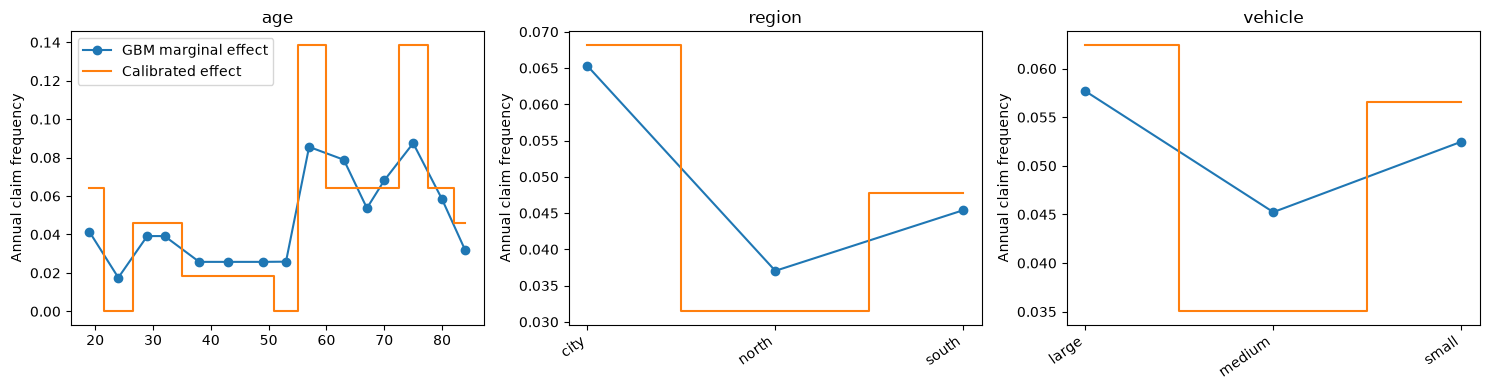

In [8]:
fig, axes = plt.subplots(1, len(effect_tables), figsize=(15, 4))
for ax, (feature, table) in zip(axes, effect_tables.items(), strict=True):
    x = np.arange(len(table)) if model.effect_curves_[feature].categorical else table[feature].astype(float)
    ax.plot(x, table['gbm_marginal_effect'], marker='o', label='GBM marginal effect')
    ax.step(x, table['tree_calibrated_effect'], where='mid', label='Calibrated effect')
    if model.effect_curves_[feature].categorical:
        ax.set_xticks(x, table[feature].astype(str), rotation=35, ha='right')
    ax.set_title(feature)
    ax.set_ylabel('Annual claim frequency')
axes[0].legend()
fig.tight_layout()
plt.show()

## 5. Evaluate the three model stages

The final model is evaluated both for accuracy and for fidelity to the GBM. Relative MSE and deviance use the GBM as 1.0, matching the normalization in the R reporting code.

In [9]:
test = splits.test
predictions = model.predict_components(test[features], test['exposure'])
intercept_rate = train['frequency'].sum() / train['exposure'].sum()
predictions = {
    'intercept': intercept_rate * test['exposure'].to_numpy(),
    **predictions,
}
metrics = model_metrics(test['frequency'].to_numpy(), predictions)
metrics

,model,mse,deviance,fidelity,relative_mse,relative_deviance
0,intercept,0.0308,214.0871,0.5032,1.0034,0.9697
1,gbm,0.0307,220.7876,1.0000,1.0000,1.0000
2,linear_glm,0.0306,211.7330,0.6646,0.9975,0.9590
3,boosted_glm,0.0313,221.5936,0.5894,1.0191,1.0037


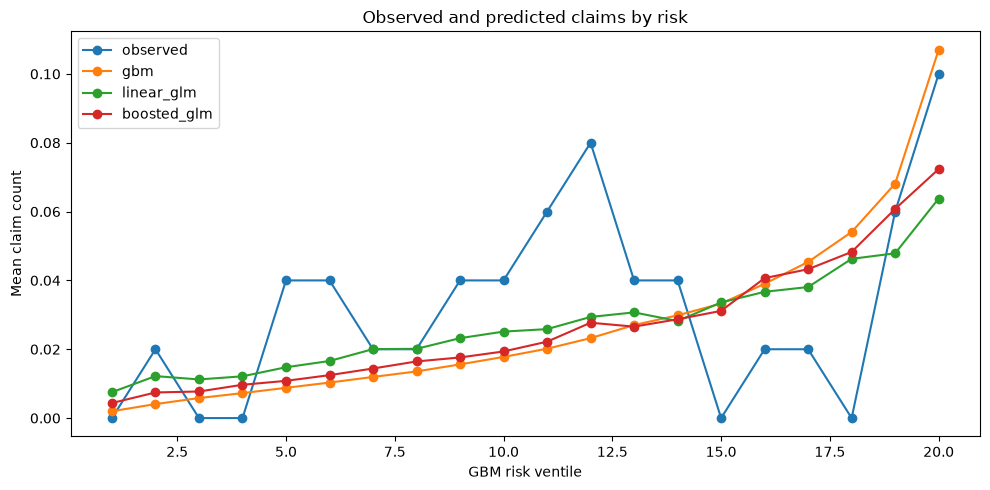

In [10]:
comparison = pd.DataFrame({
    'observed': test['frequency'].to_numpy(),
    **predictions,
})
comparison['risk_ventile'] = pd.qcut(comparison['gbm'], 20, labels=False, duplicates='drop')
by_risk = comparison.groupby('risk_ventile').mean()

fig, ax = plt.subplots(figsize=(10, 5))
for column in ['observed', 'gbm', 'linear_glm', 'boosted_glm']:
    ax.plot(by_risk.index + 1, by_risk[column], marker='o', label=column)
ax.set(xlabel='GBM risk ventile', ylabel='Mean claim count', title='Observed and predicted claims by risk')
ax.legend()
fig.tight_layout()
plt.show()

## 6. Persist and reload the complete model

The serialized object includes preprocessing, GBM, effect curves, calibration trees, interactions, and final GLM.

In [11]:
artifact_dir = Path('outputs/notebook-example')
artifact_dir.mkdir(parents=True, exist_ok=True)
model_path = artifact_dir / 'boosted_glm.joblib'
model.save(model_path)

restored = BoostedGLM.load(model_path)
original = model.predict(test[features].head(25), test['exposure'].head(25))
reloaded = restored.predict(test[features].head(25), test['exposure'].head(25))
np.testing.assert_allclose(original, reloaded)
print(f'Saved and verified: {model_path}')

Saved and verified: outputs/notebook-example/boosted_glm.joblib


## 7. Apply the same method to the original datasets

After installing the project, download the original data and run the same pipeline without changing model code:

```bash
boosting-glm download-data --output data/raw
boosting-glm train --dataset norauto --data-dir data/raw --output outputs/norauto
```

Available datasets are `freMTPL`, `auspriv`, `beMTPL`, and `norauto`. The unpublished corporate `REAL` dataset from the R project is not included.